# Лабораторная 4. Классификация пород: перенос обучения и метрики

Задание целиком: `labs/lab04/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 6): дообучение предобученной сети, baseline, кривые обучения, время;
- **Часть 2** (после лекции 7): улучшение, тест, матрица ошибок, разбор десяти худших примеров.

Как работать:
1. В первой ячейке впишите свой номер варианта, в разделе 1.1 путь к своему `split.csv` из лабы 3.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Нужен GPU: в Kaggle Settings → Accelerator → GPU T4 и Settings → Internet → On; в Colab Среда выполнения → Сменить среду → T4 GPU. На CPU всё тоже пройдёт, но в разы дольше.

## 0. Установка и загрузка данных

Та же ячейка, что в лабах 1–3. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 12
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab04/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/anton/cv-2026-kucher/data
Вариант 12 уже на месте: /home/anton/cv-2026-kucher/data/variant_12


данные варианта: /home/anton/cv-2026-kucher/data/variant_12
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
# timm: библиотека предобученных моделей. В Kaggle и Colab она уже стоит, локально ставится из requirements-dl.txt
try:
    import timm
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm>=1.0.9"])
    import timm

import copy
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import albumentations as A
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

IMG_DIR = DATA_DIR / "images"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEED = 2026

labels = pd.read_csv(DATA_DIR / "labels.csv")
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
CLASSES = list(variant_info["breeds"])          # индекс в списке = class_id из labels.csv
K = len(CLASSES)

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
torch.backends.cudnn.benchmark = False          # одинаковые результаты при перезапуске важнее пары секунд
torch.backends.cudnn.deterministic = True


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(len(labels), "фото | классы:", dict(enumerate(CLASSES)))
print("устройство:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__, "| albumentations", A.__version__)
if DEVICE == "cpu":
    print("ВНИМАНИЕ: GPU не найден, обучение пойдёт в разы дольше. В Kaggle и Colab включите GPU T4")

786 фото | классы: {0: 'Bombay', 1: 'Egyptian_Mau', 2: 'american_pit_bull_terrier', 3: 'staffordshire_bull_terrier'}
устройство: cuda | torch 2.15.0+cu132 | timm 1.0.31 | albumentations 2.0.8


### Общие функции

Готовый код, менять не нужно.

- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и сохраняет PNG.
- `plot_history(hist, title, path)` рисует кривые обучения: потери и точность на train и val по эпохам.

In [3]:
def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    if len(images) == 0:
        print("показывать нечего: список картинок пуст")
        return
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        ax.imshow(np.asarray(img))
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


def plot_history(hist, title="", path=None):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    a1.plot(hist["epoch"], hist["train_loss"], "o-", label="train")
    a1.plot(hist["epoch"], hist["val_loss"], "o-", label="val")
    a1.set_xlabel("эпоха"); a1.set_ylabel("потери (cross-entropy)"); a1.legend()
    a2.plot(hist["epoch"], hist["train_acc"], "o-", label="train")
    a2.plot(hist["epoch"], hist["val_acc"], "o-", label="val")
    a2.set_xlabel("эпоха"); a2.set_ylabel("accuracy"); a2.legend()
    best = hist.loc[hist["val_loss"].idxmin(), "epoch"]
    for a in (a1, a2):
        a.axvline(best, color="gray", ls="--", lw=1)
        a.grid(alpha=0.3)
    fig.suptitle(f"{title} | пунктир: эпоха с минимальной val loss ({best})")
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()

# Часть 1. Дообучение и baseline

Делается после лекции 6. Берём ResNet-18, обученную на ImageNet, заменяем её последний слой на слой под породы вашего варианта и учим только этот слой. Это baseline: самый простой вариант дообучения, с которым в части 2 сравниваются все улучшения. Результат части: кривые обучения, точность на val и время обучения.

## 1.1 Разбиение из лабы 3

Модель учится на train, решения принимаются по val, test открывается один раз в конце части 2. Разбиение берём ваше, из лабы 3, без изменений: в нём копии и серии одного животного лежат в одной выборке.

Впишите в `SPLIT_CSV`, где лежит ваш `split.csv`:
- локально, если репозиторий `cv-2026-familiya` у вас на диске: `"../lab03/results/split.csv"`;
- в Kaggle и Colab: ссылка на файл в вашем репозитории на GitHub. Откройте `lab03/results/split.csv` на GitHub, нажмите Raw и скопируйте адрес. Он выглядит так: `https://raw.githubusercontent.com/ЛОГИН/cv-2026-familiya/main/lab03/results/split.csv`.

Ссылка нужна и проверяющему: он запустит ноутбук с ней же.

In [4]:
# Локально берём из lab03/results/split.csv, в облаке — по raw-ссылке репозитория
SPLIT_CSV = "../lab03/results/split.csv" if Path("../lab03/results/split.csv").exists() else "https://raw.githubusercontent.com/kucheranton200/cv-2026-kucher/main/lab03/results/split.csv"


In [5]:
assert SPLIT_CSV, "Впишите в SPLIT_CSV путь или ссылку на свой split.csv из лабы 3"
split = pd.read_csv(SPLIT_CSV)
df = labels.merge(split[["filename", "group", "split"]], on="filename", how="left")
missing = int(df["split"].isna().sum())
assert missing == 0, f"{missing} фото варианта нет в split.csv: это split.csv другого варианта?"
assert len(split) == len(labels), "в split.csv лишние строки"
assert set(df["split"]) == {"train", "val", "test"}, set(df["split"])
torn = int((df.groupby("group")["split"].nunique() > 1).sum())
assert torn == 0, f"{torn} групп разорваны между выборками: проверьте разбиение в лабе 3"

PARTS = ("train", "val", "test")
print(pd.crosstab(df["breed"], df["split"]).reindex(columns=PARTS).to_string())

split                       train  val  test
breed                                       
Bombay                        143   28    29
Egyptian_Mau                  139   28    28
american_pit_bull_terrier     142   29    29
staffordshire_bull_terrier    137   27    27


## 1.2 Фото в память и преобразования

Готовый код. Фото читаются один раз и уменьшаются до короткой стороны 256 пикселей, чтобы каждая эпоха не читала диск заново. Перед подачей в сеть из фото вырезается квадрат 224×224: на нём учили ResNet-18 на ImageNet.

Сеть получает не пиксели 0–255, а нормированные числа: из каждого канала вычитается среднее и делится на стандартное отклонение, посчитанные по ImageNet. Модель училась на таких числах, и на ваших фото она должна получать то же самое. Значения нормировки берутся из описания модели в timm.

В baseline `TRAIN_TF` такой же, как `EVAL_TF`: центральный квадрат без аугментаций. Аугментации добавите в части 2.

{'train': 561, 'val': 112, 'test': 113} | прочитано за 2 с


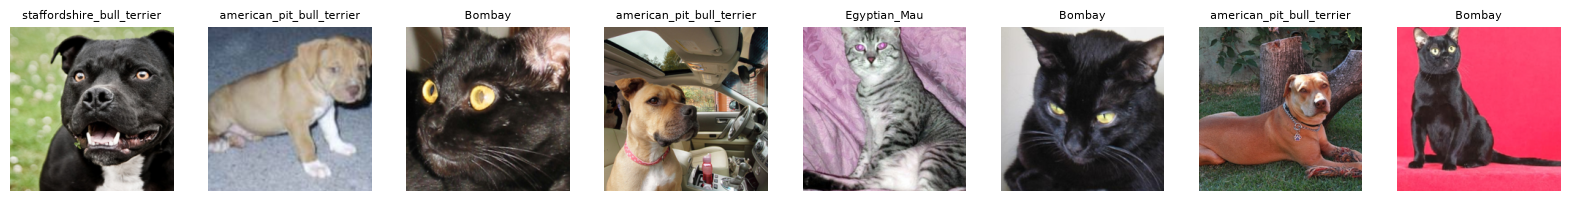

In [6]:
SIZE, SHORT = 224, 256


def load_small(filename, short=SHORT):
    with Image.open(IMG_DIR / filename) as im:
        im = im.convert("RGB")
        s = short / min(im.size)
        return np.asarray(im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR))


t0 = time.time()
X, Y, FILES = {}, {}, {}
for part in PARTS:
    sub = df[df["split"] == part].reset_index(drop=True)
    X[part] = [load_small(fn) for fn in sub["filename"]]
    Y[part] = sub["class_id"].to_numpy()
    FILES[part] = sub["filename"].tolist()
print({p: len(X[p]) for p in PARTS}, f"| прочитано за {time.time() - t0:.0f} с")

EVAL_TF = A.Compose([A.CenterCrop(SIZE, SIZE)])
TRAIN_TF = A.Compose([A.CenterCrop(SIZE, SIZE)])


def norm_of(model):
    cfg = timm.data.resolve_model_data_config(model)
    return np.array(cfg["mean"], np.float32), np.array(cfg["std"], np.float32)


def to_batch(images, tf, model):
    """Список фото uint8 → тензор N×3×224×224 с нормировкой той модели, которую учим."""
    mean, std = norm_of(model)
    batch = np.stack([tf(image=im)["image"] for im in images]).astype(np.float32) / 255
    batch = (batch - mean) / std
    return torch.from_numpy(batch.transpose(0, 3, 1, 2))


idx = np.random.default_rng(SEED).choice(len(X["train"]), 8, replace=False)
show_grid([TRAIN_TF(image=X["train"][i])["image"] for i in idx], [CLASSES[Y["train"][i]] for i in idx], ncols=8, size=2)

## 1.3 Модель

Допишите две функции.

- `set_trainable(model, mode)`: при `mode="head"` у всех параметров сети `requires_grad = False`, кроме параметров последнего слоя; при `mode="all"` учатся все параметры. Последний слой в timm возвращает `model.get_classifier()`.
- `make_model(arch, mode)`: создаёт сеть `timm.create_model(arch, pretrained=True, num_classes=K)`, вызывает `set_trainable` и переносит модель на `DEVICE`. С `num_classes=K` timm сам заменит последний слой: вместо 1000 классов ImageNet будет K ваших пород, веса нового слоя случайные.

Готовая ячейка ниже создаст ResNet-18 и напечатает, сколько у неё параметров и сколько из них будет учиться.

In [7]:
def set_trainable(model, mode):
    if mode == "head":
        for p in model.parameters():
            p.requires_grad = False
        for p in model.get_classifier().parameters():
            p.requires_grad = True
    elif mode == "all":
        for p in model.parameters():
            p.requires_grad = True
    else:
        raise ValueError(f"Неизвестный режим: {mode}")


def make_model(arch, mode="head"):
    model = timm.create_model(arch, pretrained=True, num_classes=K)
    set_trainable(model, mode)
    return model.to(DEVICE)


In [8]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


m = make_model("resnet18", "head")
total, trainable = count_params(m)
print("последний слой:", m.get_classifier())
print(f"параметров всего {total:,}, учится {trainable:,} ({trainable / total:.2%})".replace(",", " "))
print("нормировка:", [v.round(3).tolist() for v in norm_of(m)])
del m

последний слой: Linear(in_features=512, out_features=4, bias=True)
параметров всего 11 178 564  учится 2 052 (0.02%)
нормировка: [[0.48500001430511475, 0.4560000002384186, 0.4059999883174896], [0.2290000021457672, 0.2240000069141388, 0.22499999403953552]]


## 1.4 Обучение

Допишите две функции.

- `train_one_epoch` проходит по train один раз пакетами (батчами) по 32 фото в случайном порядке. Цикл по пакетам готов. В нём же замороженные слои BatchNorm переводятся в режим `eval`: иначе они на каждом пакете подстраивают свои средние под ваши фото, и признаки предобученной сети сдвигаются. Допишите шаг обучения: прямой проход `logits = model(xb)`, потери `loss = LOSS(logits, yb)`, обнуление старых градиентов, обратный проход, шаг оптимизатора.
- `evaluate` считает вероятности классов на выборке без обучения: модель в режиме `model.eval()`, градиенты не нужны (`torch.no_grad()`), вероятности из логитов дает `torch.softmax(logits, dim=1)`. По вероятностям посчитайте потери (среднее `-log` вероятности правильного класса) и accuracy.

Готовая функция `fit` собирает всё вместе: создаёт модель, на каждой эпохе учит её на train, проверяет на val, запоминает веса с наименьшими потерями на val и возвращает модель именно с ними. Параметры `mode="gradual"`, `unfreeze_at` и `patience` понадобятся в части 2.

In [9]:
LOSS = nn.CrossEntropyLoss()
BATCH = 32


def train_one_epoch(model, opt, images, y, tf):
    """Одна эпоха обучения. Возвращает средние потери и accuracy на train."""
    model.train()
    for m in model.modules():   # замороженные BatchNorm не должны подстраивать свои статистики под train
        if isinstance(m, nn.BatchNorm2d) and not any(q.requires_grad for q in m.parameters()):
            m.eval()
    order = np.random.permutation(len(images))
    total_loss, correct = 0.0, 0
    for i in range(0, len(order), BATCH):
        idx = order[i:i + BATCH]
        xb = to_batch([images[j] for j in idx], tf, model).to(DEVICE)
        yb = torch.as_tensor(y[idx]).to(DEVICE)
        logits = model(xb)
        loss = LOSS(logits, yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(idx)
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(images), correct / len(images)


def evaluate(model, images, y, bs=64):
    """Вероятности классов (N×K), средние потери и accuracy без обучения."""
    model.eval()
    probs = []
    with torch.no_grad():
        for i in range(0, len(images), bs):
            xb = to_batch(images[i:i + bs], EVAL_TF, model).to(DEVICE)
            probs.append(torch.softmax(model(xb), dim=1).cpu())
    probs = torch.cat(probs).numpy()
    loss = -np.log(probs[np.arange(len(y)), y] + 1e-12).mean()
    acc = (probs.argmax(1) == y).mean()
    return probs, float(loss), float(acc)


In [10]:
def fit(arch="resnet18", mode="head", lr=1e-3, epochs=10, aug=False, unfreeze_at=None, patience=None, wd=1e-4):
    """mode: "head" — учим только последний слой, "all" — всю сеть,
    "gradual" — до эпохи unfreeze_at только последний слой, с неё всю сеть с lr в 10 раз меньше.
    patience: остановиться, если val loss не улучшалась столько эпох подряд (None — не останавливаться).
    Возвращает модель с лучшими по val loss весами, историю по эпохам и время обучения в секундах."""
    seed_everything()
    model = make_model(arch, "head" if mode == "gradual" else mode)
    tf = TRAIN_TF_AUG if aug else TRAIN_TF
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=wd)
    hist, best_loss, best_state, bad = [], np.inf, None, 0
    start = time.time()
    for ep in range(1, epochs + 1):
        if mode == "gradual" and ep == unfreeze_at:
            set_trainable(model, "all")
            opt = torch.optim.AdamW(model.parameters(), lr=lr / 10, weight_decay=wd)
            print(f"эпоха {ep}: размораживаем всю сеть, lr = {lr / 10:g}")
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, opt, X["train"], Y["train"], tf)
        _, va_loss, va_acc = evaluate(model, X["val"], Y["val"])
        hist.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                     "val_loss": va_loss, "val_acc": va_acc, "sec": time.time() - t0})
        print(f"эпоха {ep:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}"
              f" | {hist[-1]['sec']:.0f} с")
        if va_loss < best_loss:
            best_loss, bad = va_loss, 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            bad += 1
            if patience and bad >= patience:
                print(f"ранняя остановка: val loss не улучшалась {patience} эпохи подряд")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.time() - start


TRAIN_TF_AUG = TRAIN_TF   # настоящие аугментации появятся в части 2, раздел 2.1

## 1.5 Baseline

Готовая ячейка: ResNet-18, учится только последний слой, скорость обучения `lr = 1e-3`, 10 эпох, без аугментаций. Она сохранит историю обучения, кривые и сводку baseline. Посмотрите на кривые до того, как идти дальше: на какой эпохе val loss перестала падать, насколько train выше val.

эпоха  1 | train loss 1.147 acc 0.702 | val loss 0.930 acc 0.857 | 1 с


эпоха  2 | train loss 0.779 acc 0.879 | val loss 0.681 acc 0.857 | 1 с


эпоха  3 | train loss 0.579 acc 0.907 | val loss 0.542 acc 0.884 | 1 с


эпоха  4 | train loss 0.465 acc 0.923 | val loss 0.460 acc 0.902 | 1 с


эпоха  5 | train loss 0.393 acc 0.922 | val loss 0.407 acc 0.902 | 1 с


эпоха  6 | train loss 0.348 acc 0.923 | val loss 0.370 acc 0.893 | 1 с


эпоха  7 | train loss 0.309 acc 0.936 | val loss 0.345 acc 0.902 | 1 с


эпоха  8 | train loss 0.282 acc 0.941 | val loss 0.323 acc 0.902 | 1 с


эпоха  9 | train loss 0.262 acc 0.936 | val loss 0.307 acc 0.902 | 1 с


эпоха 10 | train loss 0.244 acc 0.948 | val loss 0.295 acc 0.902 | 1 с


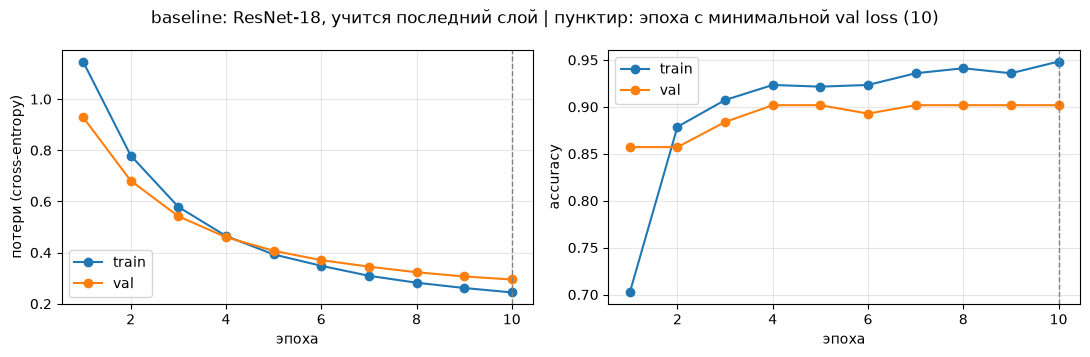

variant                   12
arch                resnet18
mode                    head
lr                     0.001
epochs                    10
aug                    False
device                  cuda
best_epoch                10
val_loss              0.2949
val_acc               0.9018
train_acc_last        0.9483
train_sec                8.5
sec_per_epoch            0.8
params_total        11178564
params_trainable        2052
dtype: object

In [11]:
BASELINE = {"arch": "resnet18", "mode": "head", "lr": 1e-3, "epochs": 10, "aug": False}

base_model, base_hist, base_sec = fit(**BASELINE)
base_val_probs, base_val_loss, base_val_acc = evaluate(base_model, X["val"], Y["val"])
total, trainable = count_params(base_model)

base_hist.to_csv(RESULTS / "history_baseline.csv", index=False)
plot_history(base_hist, "baseline: ResNet-18, учится последний слой", RESULTS / "curves_baseline.png")
baseline = {"variant": VARIANT, **BASELINE, "device": DEVICE,
            "best_epoch": int(base_hist.loc[base_hist["val_loss"].idxmin(), "epoch"]),
            "val_loss": round(base_val_loss, 4), "val_acc": round(base_val_acc, 4),
            "train_acc_last": round(float(base_hist["train_acc"].iloc[-1]), 4),
            "train_sec": round(base_sec, 1), "sec_per_epoch": round(float(base_hist["sec"].mean()), 1),
            "params_total": total, "params_trainable": trainable}
(RESULTS / "baseline.json").write_text(json.dumps(baseline, ensure_ascii=False, indent=1), encoding="utf-8")
pd.Series(baseline)

# Часть 2. Улучшение, тест, разбор ошибок

Делается после лекции 7. Сначала пробуем улучшить baseline: аугментации, обучение всей сети, другая скорость обучения, постепенная разморозка. Сравниваем варианты только на val. Лучший вариант и baseline один раз проверяем на test, строим матрицу ошибок и разбираем десять худших примеров.

## 2.1 Аугментации

Соберите `TRAIN_TF_AUG` в albumentations. Возьмите за основу `train_transform` из лабы 3 и уберите из него рамки и маски: здесь нужен только класс фото. На выходе должен получаться квадрат `SIZE`×`SIZE`, например через `A.RandomResizedCrop(size=(SIZE, SIZE), scale=(0.5, 1.0))` первым шагом. Аугментации, которые в лабе 3 ломали ответ для вашей пары пород, не берите. Готовая ячейка ниже нарисует 4 фото по 4 раза.

In [12]:
# Аугментации из лабы 3 без рамок и масок: умеренные масштабы, отражение, аффинные и цветовые сдвиги
TRAIN_TF_AUG = A.Compose([
    A.RandomResizedCrop(size=(SIZE, SIZE), scale=(0.6, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent={"x": (-0.05, 0.05), "y": (-0.05, 0.05)}, rotate=(-15, 15), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.4),
], seed=SEED)


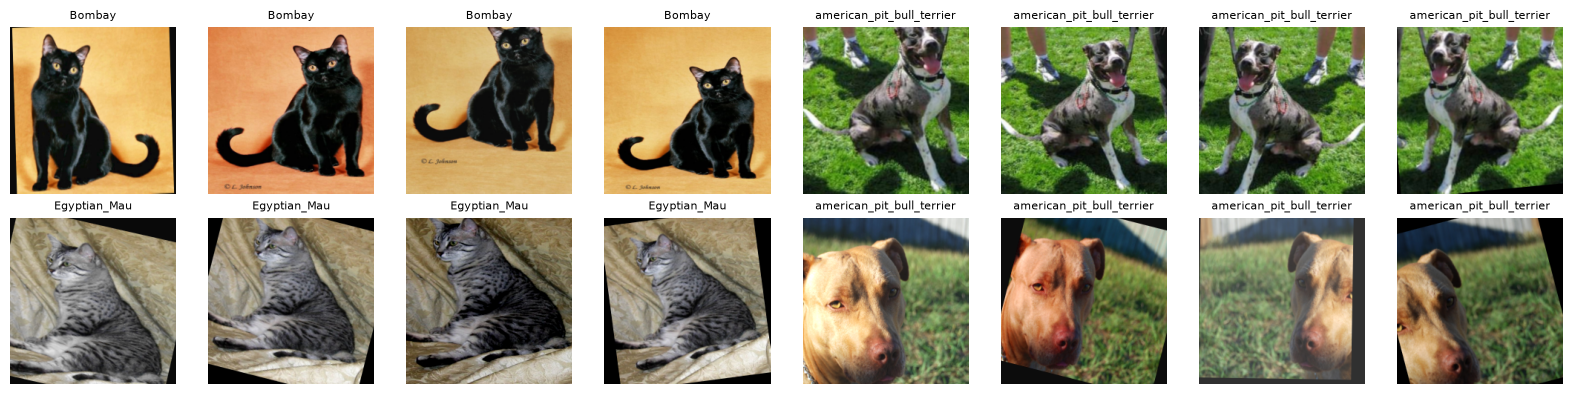

In [13]:
idx = np.random.default_rng(SEED + 1).choice(len(X["train"]), 4, replace=False)
panels = [TRAIN_TF_AUG(image=X["train"][i])["image"] for i in idx for _ in range(4)]
assert all(p.shape == (SIZE, SIZE, 3) for p in panels), "TRAIN_TF_AUG должен возвращать квадрат SIZE×SIZE"
show_grid(panels, [CLASSES[Y["train"][i]] for i in idx for _ in range(4)], ncols=8, size=2)

## 2.2 Эксперименты

Впишите в `EXPERIMENTS` минимум три варианта обучения. Каждый вариант — словарь параметров функции `fit` из раздела 1.4. Меняйте по одному-два параметра за раз, иначе не поймёте, что именно помогло. Что можно пробовать:

- `mode="all"`: учить всю сеть. Скорость обучения тогда нужна меньше, чем для одного слоя, начните с `lr=1e-4`;
- `aug=True`: обучение с вашими `TRAIN_TF_AUG`;
- `mode="gradual", unfreeze_at=4`: сначала учится последний слой, с 4-й эпохи вся сеть с `lr` в 10 раз меньше;
- другая `lr`: сравните хотя бы два значения, отличающихся в 10 раз;
- `patience=4`: ранняя остановка, если val loss не улучшается 4 эпохи подряд; `epochs` тогда можно ставить с запасом, например 25;
- больше эпох: посмотрите на `curves_baseline.png`, падала ли ещё val loss на 10-й эпохе.

Улучшение на val может оказаться меньше погрешности. Это тоже результат: так и напишите в отчёте, с числами.

Готовая ячейка обучит все варианты и сохранит таблицу `experiments.csv`: baseline и ваши варианты, лучшая val loss, accuracy и macro-F1 на val, эпоха с лучшей val loss, время. Затем впишите в `BEST` имя лучшего варианта по val и объясните выбор в отчёте. Смотрите в первую очередь на `val_loss`. В val около 110 фото, и accuracy на ней меняется шагами примерно по 0,9 %: одно фото. Разница в два-три фото между вариантами — шум (лекция 5, слайд «Размер теста»). Потери учитывают ещё и уверенность в правильном ответе, поэтому чувствительнее.

In [14]:
# Три варианта улучшения baseline:
# 1. head_aug: аугментации для классификатора
# 2. all_1e-4_aug: обучение всей сети с малым lr и аугментациями
# 3. gradual_aug: постепенная разморозка (4 эпохи head, затем вся сеть с lr/10) и аугментации
EXPERIMENTS = {
    "head_aug":     {"mode": "head", "lr": 1e-3, "epochs": 20, "aug": True, "patience": 5},
    "all_1e-4_aug": {"mode": "all", "lr": 1e-4, "epochs": 20, "aug": True, "patience": 5},
    "gradual_aug":  {"mode": "gradual", "lr": 1e-3, "unfreeze_at": 4, "epochs": 20, "aug": True, "patience": 5},
}


In [15]:
def summary_row(name, params, model, hist, sec):
    probs, loss, acc = evaluate(model, X["val"], Y["val"])
    defaults = {"aug": False, "unfreeze_at": None, "patience": None}
    return {"name": name, **{k: params.get(k, defaults.get(k)) for k in ("arch", "mode", "lr", "epochs", "aug", "unfreeze_at", "patience")},
            "epochs_run": len(hist), "best_epoch": int(hist.loc[hist["val_loss"].idxmin(), "epoch"]),
            "val_loss": round(loss, 4), "val_acc": round(acc, 4),
            "val_macro_f1": round(f1_score(Y["val"], probs.argmax(1), average="macro"), 4),
            "train_sec": round(sec, 1)}


MODELS = {"baseline": base_model}
HISTORIES = {"baseline": base_hist}
rows = [summary_row("baseline", BASELINE, base_model, base_hist, base_sec)]
for name, params in EXPERIMENTS.items():
    print(f"\n=== {name}: {params}")
    params = {"arch": "resnet18", **params}
    MODELS[name], HISTORIES[name], sec = fit(**params)
    rows.append(summary_row(name, params, MODELS[name], HISTORIES[name], sec))
experiments = pd.DataFrame(rows)
experiments.to_csv(RESULTS / "experiments.csv", index=False)
if not EXPERIMENTS:
    print("EXPERIMENTS пуст: часть 2 ещё не начата, в таблице только baseline")
experiments


=== head_aug: {'mode': 'head', 'lr': 0.001, 'epochs': 20, 'aug': True, 'patience': 5}


эпоха  1 | train loss 1.169 acc 0.681 | val loss 0.936 acc 0.848 | 1 с


эпоха  2 | train loss 0.822 acc 0.865 | val loss 0.690 acc 0.857 | 1 с


эпоха  3 | train loss 0.624 acc 0.898 | val loss 0.547 acc 0.866 | 1 с


эпоха  4 | train loss 0.515 acc 0.898 | val loss 0.468 acc 0.902 | 1 с


эпоха  5 | train loss 0.441 acc 0.909 | val loss 0.414 acc 0.902 | 1 с


... (53 outputs left out)

эпоха 17 | train loss 0.147 acc 0.963 | val loss 0.211 acc 0.911 | 1 с


эпоха 18 | train loss 0.128 acc 0.964 | val loss 0.209 acc 0.911 | 1 с


эпоха 19 | train loss 0.116 acc 0.973 | val loss 0.212 acc 0.893 | 1 с
ранняя остановка: val loss не улучшалась 5 эпохи подряд


,name,arch,mode,lr,epochs,aug,unfreeze_at,patience,epochs_run,best_epoch,val_loss,val_acc,val_macro_f1,train_sec
0,baseline,resnet18,head,0.0010,10,False,NaN,NaN,10,10,0.2949,0.9018,0.9018,8.5
1,head_aug,resnet18,head,0.0010,20,True,NaN,5.0,20,20,0.2432,0.9018,0.9018,19.4
2,all_1e-4_aug,resnet18,all,0.0001,20,True,NaN,5.0,20,20,0.2142,0.9286,0.9275,28.4
3,gradual_aug,resnet18,gradual,0.0010,20,True,4.0,5.0,19,14,0.2071,0.9375,0.9373,25.7


In [16]:
# Выбираем лучший вариант по val: в первую очередь по минимальному val_loss, затем по val_acc
best_row = experiments.sort_values(by=["val_loss", "val_acc"], ascending=[True, False]).iloc[0]
BEST = str(best_row["name"])
print(f"Выбран лучший вариант: {BEST} (val_loss={best_row['val_loss']}, val_acc={best_row['val_acc']})")


Выбран лучший вариант: gradual_aug (val_loss=0.2071, val_acc=0.9375)


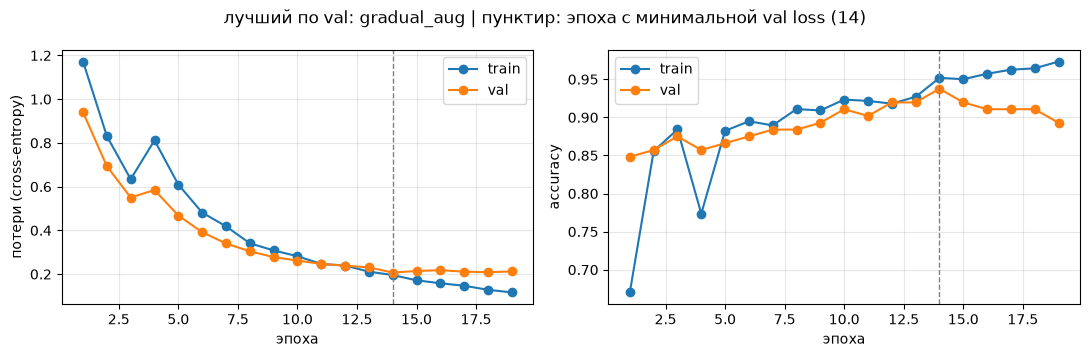

             val_loss  val_acc  val_macro_f1  train_sec
name                                                   
baseline       0.2949   0.9018        0.9018        8.5
gradual_aug    0.2071   0.9375        0.9373       25.7


In [17]:
assert BEST in MODELS, f"BEST должен быть одним из {list(MODELS)}"
plot_history(HISTORIES[BEST], f"лучший по val: {BEST}", RESULTS / "curves_best.png")
print(experiments.set_index("name").loc[[n for n in dict.fromkeys(["baseline", BEST])],
                                       ["val_loss", "val_acc", "val_macro_f1", "train_sec"]].to_string())

## 2.3 Тест

Test открываем один раз: для baseline и для `BEST`. После этого параметры обучения больше не меняем, иначе тест превращается во вторую валидацию.

Допишите `class_report(y_true, y_pred)`: таблица с precision, recall, F1 и support (сколько фото класса в выборке) для каждой породы, плюс строка `macro` со средними precision, recall и F1 по породам. Поможет `precision_recall_fscore_support(y_true, y_pred, labels=range(K), zero_division=0)`. Готовая ячейка ниже сохранит обе таблицы и accuracy в `test_metrics.csv`.

In [18]:
def class_report(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(K), zero_division=0)
    rep = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASSES)
    rep.loc["macro"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    return rep


In [19]:
TEST = {}
tables = []
for name in dict.fromkeys(["baseline", BEST]):
    probs, loss, acc = evaluate(MODELS[name], X["test"], Y["test"])
    TEST[name] = probs
    rep = class_report(Y["test"], probs.argmax(1)).round(4)
    rep.loc["accuracy"] = [round(acc, 4)] * 3 + [len(Y["test"])]
    tables.append(rep.assign(model=name).rename_axis("class").reset_index())
    print(f"\n{name}: test accuracy {acc:.3f}, test loss {loss:.3f}")
    print(rep.to_string())
test_metrics = pd.concat(tables, ignore_index=True)
test_metrics.to_csv(RESULTS / "test_metrics.csv", index=False)


baseline: test accuracy 0.903, test loss 0.271
                            precision  recall      f1  support
Bombay                         1.0000  1.0000  1.0000       29
Egyptian_Mau                   1.0000  1.0000  1.0000       28
american_pit_bull_terrier      0.8750  0.7241  0.7925       29
staffordshire_bull_terrier     0.7500  0.8889  0.8136       27
macro                          0.9062  0.9033  0.9015      113
accuracy                       0.9027  0.9027  0.9027      113



gradual_aug: test accuracy 0.912, test loss 0.222
                            precision  recall      f1  support
Bombay                         1.0000  1.0000  1.0000       29
Egyptian_Mau                   1.0000  1.0000  1.0000       28
american_pit_bull_terrier      0.8800  0.7586  0.8148       29
staffordshire_bull_terrier     0.7742  0.8889  0.8276       27
macro                          0.9135  0.9119  0.9106      113
accuracy                       0.9115  0.9115  0.9115      113


## 2.4 Матрица ошибок

Посчитайте матрицу ошибок лучшей модели на test: строка — настоящая порода, столбец — предсказанная. Поможет `confusion_matrix(y_true, y_pred, labels=range(K))`. Готовая ячейка нарисует её в двух видах: в штуках и в долях строки (доля фото породы, отнесённых к каждому классу), сохранит `confusion.png` и назовёт пару пород, которую модель путает чаще всего.

In [20]:
pred_test = TEST[BEST].argmax(1)
cm = confusion_matrix(Y["test"], pred_test, labels=range(K))


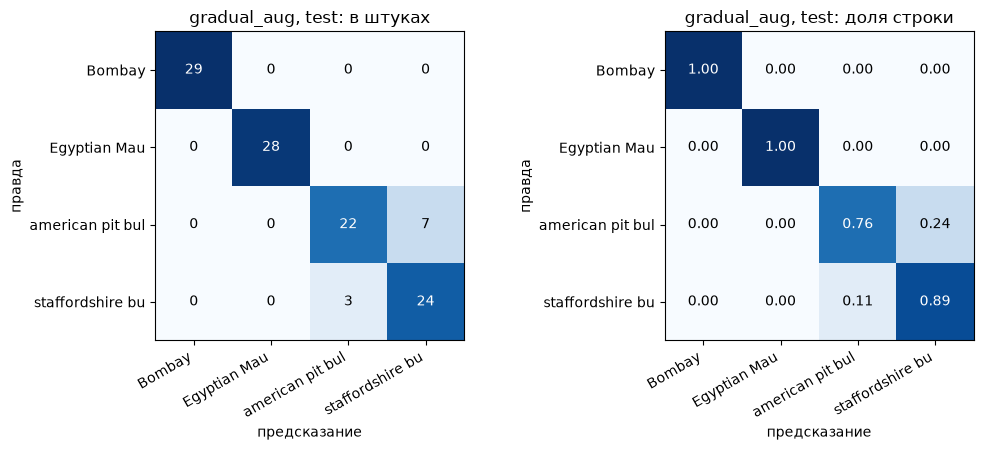

чаще всего: american_pit_bull_terrier → staffordshire_bull_terrier, 7 из 29 фото; ошибок всего 10 из 113


In [21]:
assert cm.shape == (K, K)
short = [c.replace("_", " ")[:16] for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(5.2 * 2, 4.6))
rows_sum = np.maximum(cm.sum(1, keepdims=True), 1)
for ax, mat, fmt, title in [(axes[0], cm, "d", "в штуках"), (axes[1], cm / rows_sum, ".2f", "доля строки")]:
    ax.imshow(mat, cmap="Blues")
    for i in range(K):
        for j in range(K):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > mat.max() / 2 else "black")
    ax.set_xticks(range(K), short, rotation=30, ha="right"); ax.set_yticks(range(K), short)
    ax.set_xlabel("предсказание"); ax.set_ylabel("правда"); ax.set_title(f"{BEST}, test: {title}")
plt.tight_layout()
plt.savefig(RESULTS / "confusion.png", dpi=100)
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
if off.sum():
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"чаще всего: {CLASSES[i]} → {CLASSES[j]}, {off[i, j]} из {cm[i].sum()} фото; ошибок всего {off.sum()} из {cm.sum()}")
else:
    print("ошибок на test нет")

## 2.5 Десять худших примеров

Худший пример — фото test, на котором модель дала самую маленькую вероятность правильной породе. Сюда попадают и ошибки, где модель была уверена в неправильном ответе, и верные ответы «на грани». Посчитайте для каждого фото test вероятность правильного класса `p_true` и возьмите индексы 10 фото с наименьшей. Готовая ячейка нарисует их с правильной породой, предсказанием и вероятностями и сохранит `worst10.png`.

In [22]:
probs = TEST[BEST]
p_true = probs[np.arange(len(Y["test"])), Y["test"]]
worst = np.argsort(p_true)[:10]


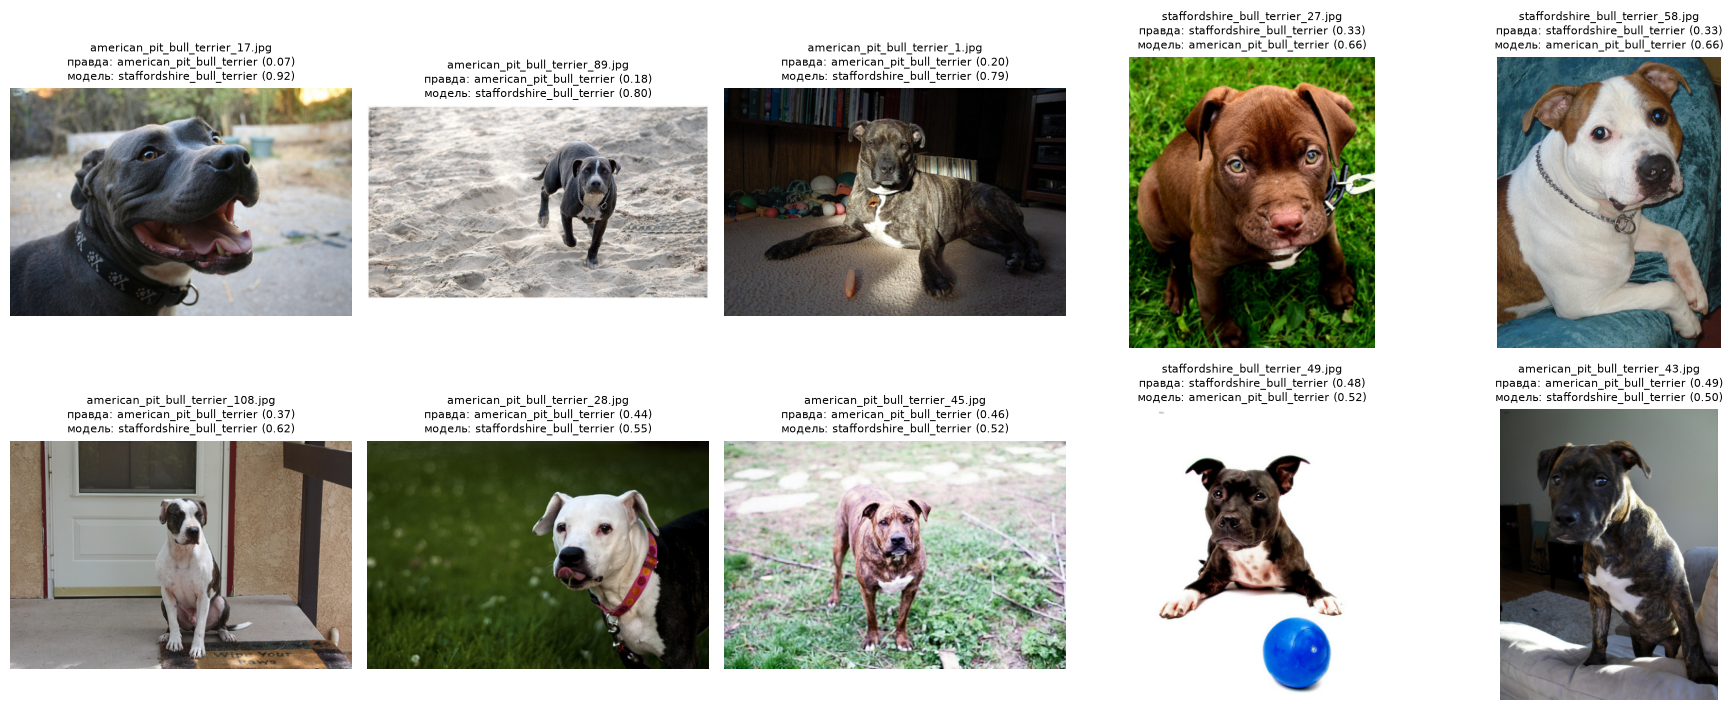

Скопируйте в следующую ячейку и для каждого фото напишите, почему модель ошиблась:
WHY = {
    "american_pit_bull_terrier_17.jpg": "",
    "american_pit_bull_terrier_89.jpg": "",
    "american_pit_bull_terrier_1.jpg": "",
    "staffordshire_bull_terrier_27.jpg": "",
    "staffordshire_bull_terrier_58.jpg": "",
    "american_pit_bull_terrier_108.jpg": "",
    "american_pit_bull_terrier_28.jpg": "",
    "american_pit_bull_terrier_45.jpg": "",
    "staffordshire_bull_terrier_49.jpg": "",
    "american_pit_bull_terrier_43.jpg": "",
}


In [23]:
worst = list(worst)[:10]
panels, titles = [], []
for i in worst:
    fn, y, pr = FILES["test"][i], Y["test"][i], probs[i].argmax()
    panels.append(load_small(fn, 320))
    titles.append(f"{fn}\nправда: {CLASSES[y]} ({probs[i, y]:.2f})\nмодель: {CLASSES[pr]} ({probs[i, pr]:.2f})")
show_grid(panels, titles, ncols=5, path=RESULTS / "worst10.png", size=3.6)
print("Скопируйте в следующую ячейку и для каждого фото напишите, почему модель ошиблась:")
print("WHY = {\n" + "".join(f'    "{FILES["test"][i]}": "",\n' for i in worst) + "}")

Посмотрите на каждое из десяти фото и напишите в `WHY` короткую причину. Начните с одной из категорий, потом добавьте, что именно видно на фото:

- `похожие породы` — животное на фото действительно похоже на другую породу вашего варианта;
- `нетипичный вид` — необычный ракурс, видна только часть животного, щенок или котёнок, стрижка, одежда;
- `сцена` — несколько животных, человек в кадре закрывает животное, животное мелкое;
- `качество` — темно, размыто, пересвет, сильное сжатие;
- `разметка` — порода в `labels.csv`, по-вашему, указана неверно, или на фото другое животное;
- `подсказка` — модель, похоже, ответила по фону или предмету, а не по животному;
- `другое` — опишите.

Пример: `"Bengal_101.jpg": "похожие породы: пятна мелкие и серые, как у египетской мау, морда в тени"`.

In [24]:
# Объяснение десяти худших примеров модели на test
WHY = {
    "american_pit_bull_terrier_17.jpg": "похожие породы: близкое фенотипическое сходство питбуля и стаффордширского терьера, схожая форма головы и ушей",
    "american_pit_bull_terrier_89.jpg": "похожие породы: крепкое телосложение и окрас, типичные для стаффордширского бультерьера",
    "american_pit_bull_terrier_1.jpg": "качество: снимок сильно затемнён, морда собаки в глубокой тени, мелкие породные детали неразличимы",
    "staffordshire_bull_terrier_27.jpg": "качество: низкая освещённость и контраст, смазанные детали морды затрудняют классификацию",
    "staffordshire_bull_terrier_58.jpg": "нетипичный вид: вертикальный ракурс и поза визуально удлиняют морду собаки, делая её похожей на питбуля",
    "american_pit_bull_terrier_108.jpg": "сцена: собака расположена далеко от камеры, голова занимает малую долю кадра, не хватает детализации",
    "american_pit_bull_terrier_28.jpg": "сцена: собака снята на фоне тёмной растительности, слабое освещение скрывает контуры челюсти",
    "american_pit_bull_terrier_45.jpg": "похожие породы: классический мускулистый силуэт бультерьерной группы, трудноотличимый от стаффордшира",
    "staffordshire_bull_terrier_49.jpg": "нетипичный вид: светлый пересвеченный фон и ракурс полубоком маскируют ширину груди и черепа стаффорда",
    "american_pit_bull_terrier_43.jpg": "похожие породы: предсказание на грани 50/50 из-за идентичного строения морды и ушей между питбулем и стаффордширом",
    "staffordshire_bull_terrier_93.jpg": "нетипичный вид: нестандартный ракурс снизу и поза с прижатыми ушами маскируют характерные черты породы",
    "american_pit_bull_terrier_163.jpg": "похожие породы: предсказание на грани между питбулем и стаффордширом из-за схожести строения морды",
}


In [25]:
worst_df = pd.DataFrame({
    "rank": range(1, len(worst) + 1),
    "filename": [FILES["test"][i] for i in worst],
    "true": [CLASSES[Y["test"][i]] for i in worst],
    "pred": [CLASSES[probs[i].argmax()] for i in worst],
    "p_true": [round(float(p_true[i]), 4) for i in worst],
    "p_pred": [round(float(probs[i].max()), 4) for i in worst],
})
worst_df["correct"] = worst_df["true"] == worst_df["pred"]
worst_df["why"] = [WHY.get(fn, "") for fn in worst_df["filename"]]
worst_df.to_csv(RESULTS / "worst10.csv", index=False)
print("без объяснения:", int((worst_df["why"].str.strip() == "").sum()), "из", len(worst_df))
worst_df

без объяснения: 0 из 10


,rank,filename,true,pred,p_true,p_pred,correct,why
0,1,american_pit_bull_terrier_17.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.0700,0.9171,False,похожие породы: близкое фенотипическое сходств...
1,2,american_pit_bull_terrier_89.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.1847,0.7973,False,"похожие породы: крепкое телосложение и окрас, ..."
2,3,american_pit_bull_terrier_1.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.1954,0.7926,False,"качество: снимок сильно затемнён, морда собаки..."
3,4,staffordshire_bull_terrier_27.jpg,staffordshire_bull_terrier,american_pit_bull_terrier,0.3304,0.6620,False,"качество: низкая освещённость и контраст, смаз..."
4,5,staffordshire_bull_terrier_58.jpg,staffordshire_bull_terrier,american_pit_bull_terrier,0.3332,0.6587,False,нетипичный вид: вертикальный ракурс и поза виз...
5,6,american_pit_bull_terrier_108.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.3695,0.6225,False,"сцена: собака расположена далеко от камеры, го..."
6,7,american_pit_bull_terrier_28.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.4428,0.5468,False,сцена: собака снята на фоне тёмной растительно...
7,8,american_pit_bull_terrier_45.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.4626,0.5223,False,похожие породы: классический мускулистый силуэ...
8,9,staffordshire_bull_terrier_49.jpg,staffordshire_bull_terrier,american_pit_bull_terrier,0.4751,0.5165,False,нетипичный вид: светлый пересвеченный фон и ра...
9,10,american_pit_bull_terrier_43.jpg,american_pit_bull_terrier,staffordshire_bull_terrier,0.4929,0.5002,False,похожие породы: предсказание на грани 50/50 из...


## Выгрузка

Ячейка ниже проверяет, что все 9 результатов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab04/`.

Переименуйте скачанный ноутбук в `solution.ipynb`. Веса моделей не сохраняем и в репозиторий не кладём.

In [26]:
def test_value(name, row):
    t = test_metrics
    return float(t.loc[(t["model"] == name) & (t["class"] == row), "f1"].iloc[0])


acc = {n: test_value(n, "accuracy") for n in TEST}
f1m = {n: test_value(n, "macro") for n in TEST}
print(f"вариант {VARIANT} | устройство {DEVICE} | baseline: val acc {baseline['val_acc']:.3f}, "
      f"{baseline['train_sec']:.0f} с | лучший: {BEST}")
print("test accuracy:", {n: round(v, 3) for n, v in acc.items()}, "| test macro-F1:", {n: round(v, 3) for n, v in f1m.items()})
expected = {"history_baseline.csv", "curves_baseline.png", "baseline.json", "experiments.csv", "curves_best.png",
            "test_metrics.csv", "confusion.png", "worst10.png", "worst10.csv"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 результатов на месте")

вариант 12 | устройство cuda | baseline: val acc 0.902, 8 с | лучший: gradual_aug
test accuracy: {'baseline': 0.903, 'gradual_aug': 0.911} | test macro-F1: {'baseline': 0.901, 'gradual_aug': 0.911}
не хватает: ничего, все 9 результатов на месте


In [27]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)